In [4]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

O Dendrograma é a representação visual do algoritmo de Clusterização Hierárquica. Diferente do K-Means, que força os dados a entrarem em um número fixo de grupos, o dendrograma mostra a "história" completa de como os alunos se relacionam, desde o nível individual até o grupo inteiro.Quanto maior a linha vertical sem cruzar com uma linha horizontal, maior é a distinção entre aquele grupo e os outros. O numero de clusters é obtido pela quantidade de linhas que cruza a linha horizontal gerada (y = 24) e o numero foi clusters = 3.

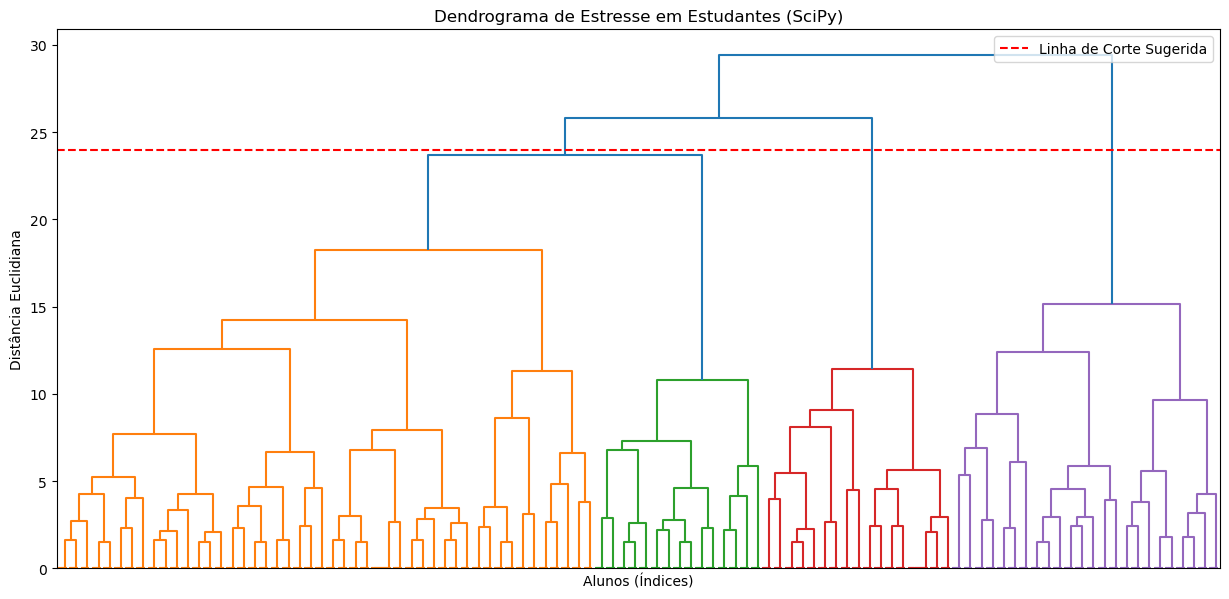

In [8]:

df = pd.read_csv("StudentStress.csv")
X = df.drop(columns=['Kindly Rate your Sleep Quality '])

X_std = StandardScaler().fit_transform(X)

linked = linkage(X_std, method='ward')


plt.figure(figsize=(15, 7))
plt.title('Dendrograma de Estresse em Estudantes (SciPy)')
plt.xlabel('Alunos (Índices)')
plt.ylabel('Distância Euclidiana')


dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True,
           no_labels=True)

plt.axhline(y=24, c='r', ls='--', label='Linha de Corte Sugerida')
plt.legend()
plt.show()

Foi feito aqui o metodo t-SNE, ele é um metodo que tambem reduz a dimensionalidade que serve para dados nao lineares e complexos.Ele é mais custoso que o PCA e seu objetivo é prevalecer os alunos vizinhos mesmo que tenha que distorcer a distancia.O t-sne usa probabilidade,ele mede a distância entre um aluno e todos os outros e converte isso em uma probabilidade de "ser vizinho" (usando uma Curva Gaussiana). Alunos próximos têm alta probabilidade; alunos distantes, baixa.

Dados carregados.
Analisando 520 alunos e 5 variáveis.
Rodando t-SNE


c:\Users\Irisd\anaconda3\Lib\site-packages\sklearn\manifold\_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


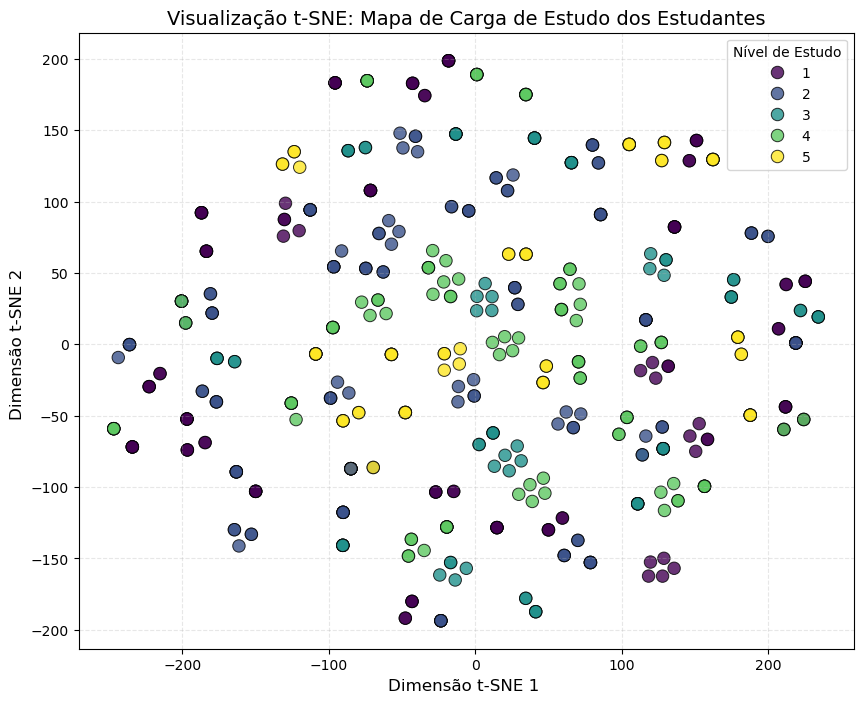

In [ ]:



df = pd.read_csv('StudentStress.csv')



X = df.drop(columns=['how would you rate your study load?'])
y = df['how would you rate your study load?']

print("Dados carregados.")
print(f"Analisando {X.shape[0]} alunos e {X.shape[1]} variáveis.")


scaler = StandardScaler()
X_std = scaler.fit_transform(X)


print("Rodando t-SNE")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
X_tsne = tsne.fit_transform(X_std)


df_tsne = pd.DataFrame(data=X_tsne, columns=['Dimensão 1', 'Dimensão 2'])
df_tsne['Nivel_Estudo'] = y

plt.figure(figsize=(10, 8))


sns.scatterplot(
    data=df_tsne,
    x='Dimensão 1',
    y='Dimensão 2',
    hue='Nivel_Estudo',
    palette='viridis',    
    s=80,                  
    alpha=0.8,          
    edgecolor='black'      
)

plt.title('Visualização t-SNE: Mapa de Carga de Estudo dos Estudantes', fontsize=14)
plt.xlabel('Dimensão t-SNE 1 ', fontsize=12)
plt.ylabel('Dimensão t-SNE 2 ', fontsize=12)
plt.legend(title='Nível de Estudo')
plt.grid(True, linestyle='--', alpha=0.3)

plt.show()

O gráfico t-SNE revela que existem padrões de comportamento bem definidos e distintos entre os estudantes que relatam diferentes cargas de estudo. A formação de clusters coerentes (ilhas de mesma cor) prova que as variáveis de saúde e acadêmicas conseguem explicar e diferenciar a percepção de carga de estudo, mas essa relação é complexa e não-linear, exigindo métodos avançados para ser detectada.